### 1. Load libraries

In [1]:
import numpy as np
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from processing import ExperimentalValidation

### 2. Analysis of raw data

In [2]:
phi_data = ExperimentalValidation(path_to_data=r'D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\OLEOSIM_Thermodynamics\Unifac_Dortmund\Experimental_Data\data\raw_lle_data.xlsx', 
                                            component_list=['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER'], 
                                            column_list_to_remove=['Ref', 'Sub Ref', 'Temperature (K)', 'Type Alcohol'],
                                            error_threshold=0.20).calculate_phi()


In [3]:
tie_lines_per_reference = phi_data.group_by('Ref').len().sort(by='Ref').select('len').mean()
tie_lines_per_reference

len
f64
25.754386


In [4]:
tie_lines_per_subreference = phi_data.group_by(['Ref', 'Sub Ref']).len().sort(by='Ref').select('len').mean()
tie_lines_per_subreference

len
f64
10.338028


In [5]:
temperature_range = phi_data.select('Temperature (K)').max() - phi_data.select('Temperature (K)').min()
temperature_range

Temperature (K)
f64
70.0


In [6]:
temperature_tie_lines = phi_data.group_by('Temperature (K)').len().sort(by='Temperature (K)')

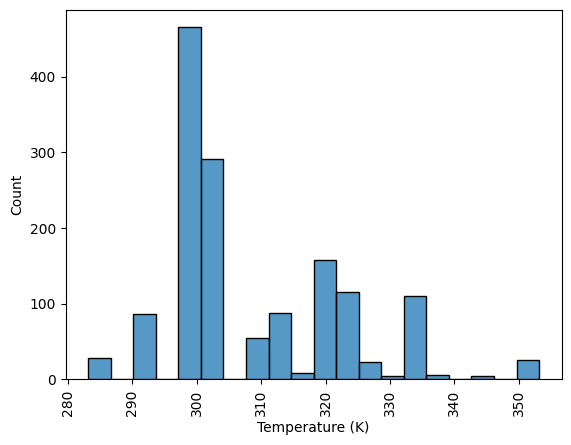

In [7]:
sns.histplot(data = phi_data, x = 'Temperature (K)')
plt.xticks(rotation = 90)
plt.show()

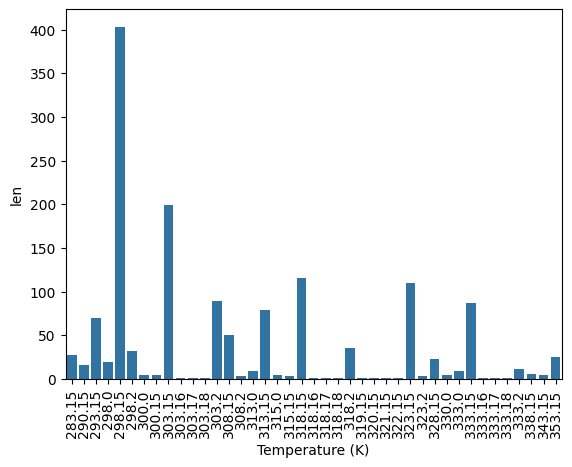

In [8]:
sns.barplot(data = temperature_tie_lines, x = 'Temperature (K)', y = 'len')
plt.xticks(rotation = 90)
plt.show()

In [9]:
tie_lines_per_alcohol = phi_data.group_by('Type Alcohol').len().sort(by='Type Alcohol')
tie_lines_per_alcohol

Type Alcohol,len
i64,u32
0,46
1,431
2,967
3,6
4,18


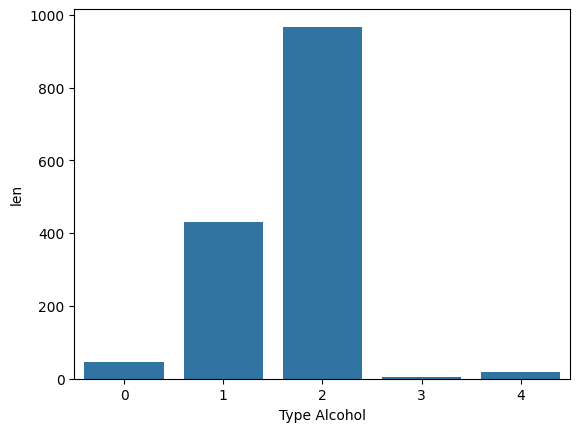

In [10]:
sns.barplot(data = tie_lines_per_alcohol, x = 'Type Alcohol', y = 'len')
plt.show()

In [14]:
columns_to_select = ['phi_FAME/FAEE', 'phi_GLYCEROL', 'phi_ALCOHOL', 'phi_OIL', 'phi_DAG', 'phi_MAG', 'phi_ACID','phi_WATER']

In [ ]:
type

In [17]:
def mean_excluding_zeros(row):
    non_zero_values = [val for val in row if val != 0]
    if not non_zero_values:
        return None  # or return float('nan') if you prefer NaN
    return sum(non_zero_values) / len(non_zero_values)

In [23]:
experimental_phi = phi_data.with_columns(
    pl.concat_list(columns_to_select).map_elements(mean_excluding_zeros, return_dtype= float).alias('Experimental mean phi')
)


In [29]:
experimental_phi.filter((pl.col('Experimental mean phi') >=1) | (pl.col('Experimental mean phi') <=0)).shape[0]

55

In [30]:
def absolute_errors(row, mean):
    return [abs(val - mean) if val != 0 else None for val in row]

In [36]:
df = experimental_phi.with_columns(
    pl.concat_list(columns_to_select).map_elements(
        lambda row: absolute_errors(row, mean_excluding_zeros(row)),
    return_dtype=list[float]).alias('abs_errors')
)


In [40]:
def mean_non_null(values):
    non_null_values = [val for val in values if val is not None]
    if not non_null_values:
        return None  # or return float('nan') if you prefer NaN
    return sum(non_null_values) / len(non_null_values)

# Calculate average absolute error for each row
df = df.with_columns(
    df['abs_errors'].map_elements(mean_non_null, return_dtype=float).alias('average_absolute_error')
)

In [43]:
df.filter((pl.col('average_absolute_error') >0.20))

index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi,abs_errors,average_absolute_error
u32,i64,str,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,list[f64],f64
2,1,"""a""",298.15,1,0.35,0.35,0.3,0.0,0.0,0.0,0.0,0.0,0.9223,0.0014,0.0763,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0012,0.7829,0.2159,0.0,0.0,0.0,0.0,0.0,0.378678,0.553935,-0.602436,0.0,0.0,0.0,0.0,0.0,0.110059,"[0.268619, 0.443876, … null]",0.474996
4,1,"""a""",298.15,1,0.42,0.42,0.16,0.0,0.0,0.0,0.0,0.0,0.8158,0.0397,0.1445,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.002,0.6188,0.3792,0.0,0.0,0.0,0.0,0.0,0.51364,0.343291,0.933958,0.0,0.0,0.0,0.0,0.0,0.596963,"[0.083323, 0.253672, … null]",0.224663
7,2,"""a""",293.15,2,0.4902,0.4768,0.033,0.0,0.0,0.0,0.0,0.0,0.9305,0.0219,0.0476,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0248,0.9309,0.0443,0.0,0.0,0.0,0.0,0.0,0.513857,0.49956,-3.424242,0.0,0.0,0.0,0.0,0.0,-0.803609,"[1.317465, 1.303169, … null]",1.747089
119,8,"""a""",333.15,1,0.4765,0.4858,0.0377,0.0,0.0,0.0,0.0,0.0,0.9632,0.0011,0.0357,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0041,0.7449,0.251,0.0,0.0,0.0,0.0,0.0,0.492545,0.348346,0.990711,0.0,0.0,0.0,0.0,0.0,0.610534,"[0.117989, 0.262188, … null]",0.253451
121,8,"""a""",333.15,1,0.4156,0.4249,0.1595,0.0,0.0,0.0,0.0,0.0,0.9901,0.0013,0.0086,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.011,0.9279,0.0611,0.0,0.0,0.0,0.0,0.0,0.413237,0.542845,-1.874286,0.0,0.0,0.0,0.0,0.0,-0.306068,"[0.719305, 0.848913, … null]",1.045478
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
1275,49,"""a""",318.2,2,0.0601,0.0,0.47,0.428,0.0082,0.0129,0.0203,0.0,0.0676,1.0000e-20,0.286,0.612,0.0111,0.0074,0.0167,1.0000e-20,0.0501,0.0,0.749,0.152,0.0095,0.0168,0.0223,0.0,0.571429,0.0,0.602592,0.6,-0.8125,0.414894,0.357143,0.0,0.288926,"[0.282502, null, … null]",0.367142
1284,49,"""b""",318.2,2,0.0308,0.0,0.466,0.454,0.0144,0.0128,0.0221,0.0,0.035,1.0000e-20,0.281,0.639,0.0168,0.0076,0.0214,1.0000e-20,0.0209,0.0,0.773,0.154,0.0097,0.0115,0.0304,0.0,0.702128,0.0,0.623984,0.618557,0.661972,-0.333333,0.922222,0.0,0.532588,"[0.16954, null, … null]",0.28864
1304,50,"""a""",303.2,2,0.0,0.0,0.499,0.393,0.005,0.0,0.102,0.0,1.0000e-20,1.0000e-20,0.26,0.657,0.006,1.0000e-20,0.078,1.0000e-20,0.0,0.0,0.673,0.193,0.006,0.0,0.129,0.0,0.0,0.0,0.421308,0.431034,-inf,0.0,0.529412,0.0,-inf,"[null, null, … null]",NaN


<Axes: ylabel='Count'>

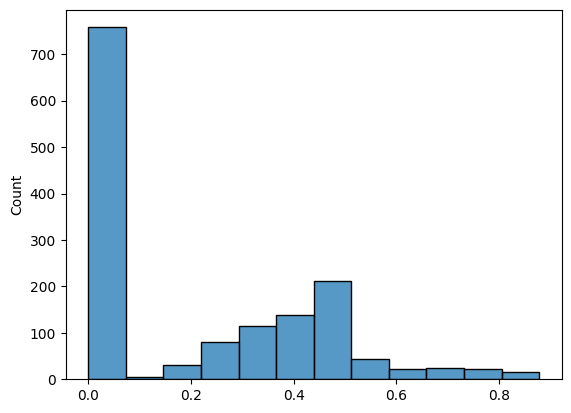

In [63]:
sns.histplot(x = df.select(pl.col('phi_FAME/FAEE')).to_numpy().reshape(1468))

In [62]:
df.select(pl.col('phi_FAME/FAEE')).to_numpy().reshape(1468)

array([0.46403683, 0.45160925, 0.37867767, ..., 0.        , 0.        ,
       0.        ])

### 3.Analysis of refined data

In [2]:
thresholds = [0.05, 0.1, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.5, 0.55, 0.65, 0.70, 0.75]
lengths = []
for i in thresholds:
    validated_data = ExperimentalValidation(path_to_data=r'D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\OLEOSIM_Thermodynamics\Unifac_Dortmund\Experimental_Data\data\raw_lle_data.xlsx', 
                                            component_list=['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER'], 
                                            column_list_to_remove=['Ref', 'Sub Ref', 'Temperature (K)', 'Type Alcohol'],
                                            error_threshold=0.20)._calculate_experimental_phi()
    lengths.append(validated_data.shape[0])
    
    

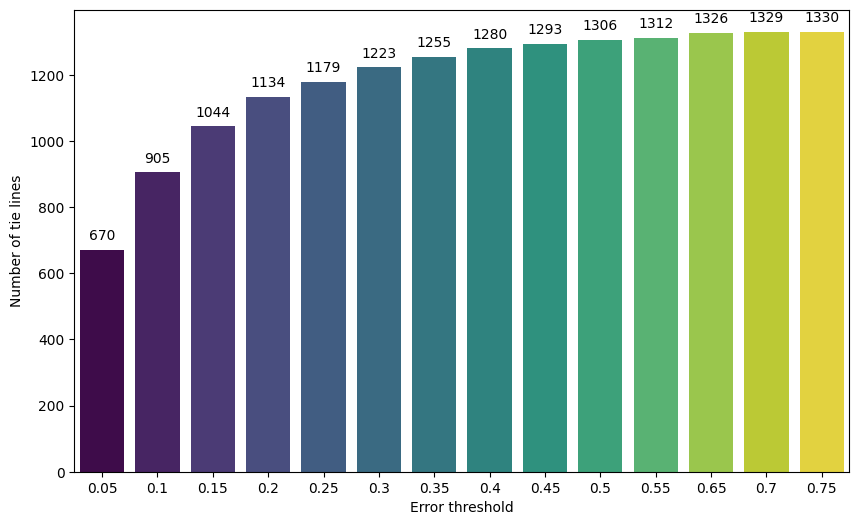

In [3]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=thresholds, y=lengths, palette='viridis', hue=thresholds, legend=False)

# Annotate the bars with the values
for p in ax.patches:
    ax.annotate(f'{p.get_height():.0f}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 10), 
                textcoords='offset points')

# Set labels and title
ax.set_xlabel('Error threshold')
ax.set_ylabel('Number of tie lines')

# Show the plot
plt.show()

In [23]:
raw_data = (pl.read_excel(r'D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\OLEOSIM_Thermodynamics\Unifac_Dortmund\Experimental_Data\data\raw_lle_data.xlsx', engine='calamine'))
